# Base-Paper-Inspired Philadelphia Crime Classification

## 1. Research Objective

This experiment adapts the crime-type classification methodology of the base paper to the Philadelphia 2018–2022 dataset. It trains six supervised classifiers to predict the grouped `crime_group` target from temporal, geographic, and policing-area attributes. This is a base-paper-inspired implementation, not an exact replication.

## 2. Experiment Configuration and Reproducibility

The baseline uses a stratified 70%/30% train/test split with `random_state=42`. Preprocessing is fitted on training data only. No class balancing or hyperparameter search is performed. Models are trained sequentially.

## Methodological Note: Crime-Class Grouping

The source dataset contains 32 original `text_general_code` labels. Following the teacher’s project-specific requirement, semantically related labels were grouped into 14 broader categories. The original `text_general_code` column is retained for traceability, while **`crime_group` is the modeling target**. The mapping and rationale are documented in `02_Crime_Class_Grouping.ipynb`. This grouping is a project-specific methodological modification; these exact 14 categories are not attributed to the source paper.

## 3. Imports and Model Implementations

Reusable model implementations remain in the six Python modules under `models/`; this notebook controls the research experiment.

In [1]:
import time
import warnings
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

try:
    from _bootstrap import ensure_project_root
except ModuleNotFoundError:
    from notebooks._bootstrap import ensure_project_root
project_root = ensure_project_root()
from src.config import (GROUPED_DATASET, RESULTS_DIR, TARGET_GROUPED,
                        RANDOM_STATE, TEST_SIZE, NUMERICAL_FEATURES,
                        CATEGORICAL_FEATURES, IDENTIFIER_COLUMNS, LEAKAGE_COLUMNS)
from src.data_loader import load_grouped_philadelphia_data
from src.data_validation import check_target_leakage, validate_target
from src.feature_engineering import create_temporal_features
from src.preprocessing import (build_preprocessor, build_model_pipeline,
                               create_train_test_split, identify_feature_types)
from src.evaluation import (evaluate_multiclass_model, generate_classification_report,
                            create_confusion_matrix_data, add_model_result,
                            create_model_comparison_table)
from src.visualization import (plot_confusion_matrix, plot_model_comparison,
                               plot_weighted_metrics, plot_model_metric_summary)
from models.xgboost_model import create_model as create_xgboost_model
from models.catboost_model import create_model as create_catboost_model
from models.random_forest_model import create_model as create_random_forest_model
from models.decision_tree_model import create_model as create_decision_tree_model
from models.mlp_model import create_model as create_mlp_model
from models.knn_model import create_model as create_knn_model

pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")
print(f"Python: {platform.python_version()} | pandas: {pd.__version__} | NumPy: {np.__version__}")


Python: 3.11.9 | pandas: 2.3.3 | NumPy: 2.0.2


## 4. Dataset Loading and Verification

The canonical combined CSV is loaded with a project-relative path. Its source file is not modified.

In [2]:
df = load_grouped_philadelphia_data(low_memory=False)
target = TARGET_GROUPED
required_columns = [target, "text_general_code"]
missing_required = [c for c in required_columns if c not in df.columns]
if missing_required:
    raise KeyError(f"Required columns are missing: {missing_required}")
print("Grouped dataset:", GROUPED_DATASET.relative_to(project_root))
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Grouped dataset: dataset\processed\Philadelphia_Crime_Incidents_2018_2022_Grouped.csv
Shape: (736033, 21)
Columns: ['source_year', 'objectid', 'dc_dist', 'psa', 'dispatch_date_time', 'dispatch_date', 'dispatch_time', 'hour', 'dc_key', 'location_block', 'ucr_general', 'text_general_code', 'point_x', 'point_y', 'gdb_geomattr_data', 'lat', 'lng', 'the_geom', 'cartodb_id', 'the_geom_webmercator', 'crime_group']


,source_year,objectid,dc_dist,psa,dispatch_date_time,dispatch_date,dispatch_time,hour,dc_key,location_block,...,text_general_code,point_x,point_y,gdb_geomattr_data,lat,lng,the_geom,cartodb_id,the_geom_webmercator,crime_group
0,2018,119,39,2,2018-05-11 04:00:00+00,2018-05-11,00:00:00,22.0,2.010391e+11,2100 BLOCK WINDRIM,...,Homicide - Criminal,-75.159510,40.022313,NaN,40.022313,-75.159510,NaN,NaN,NaN,Homicide-Related Offenses
1,2018,18377,8,1,2018-05-25 04:00:00+00,2018-05-25,00:00:00,11.0,2.018080e+11,8100 BLOCK CRESCO AV,...,Homicide - Criminal,-75.029052,40.048675,NaN,40.048675,-75.029052,NaN,NaN,NaN,Homicide-Related Offenses
2,2018,20003,15,2,2018-06-28 04:00:00+00,2018-06-28,00:00:00,18.0,2.018150e+11,1900 BLOCK E CHELTENHAM AV,...,Homicide - Criminal,-75.065510,40.018049,NaN,40.018049,-75.065510,NaN,NaN,NaN,Homicide-Related Offenses
3,2018,20014,5,3,2018-08-06 04:00:00+00,2018-08-06,00:00:00,18.0,2.018050e+11,4500 BLOCK WILDE ST,...,Homicide - Criminal,-75.225237,40.028996,NaN,40.028996,-75.225237,NaN,NaN,NaN,Homicide-Related Offenses
4,2018,20023,12,3,2018-08-18 04:00:00+00,2018-08-18,00:00:00,20.0,2.018121e+11,5200 BLOCK WOODLAND AV,...,Homicide - Criminal,-75.216455,39.938066,NaN,39.938067,-75.216455,NaN,NaN,NaN,Homicide-Related Offenses


## 5. Grouped Target and Class Distribution

The grouped target contains the teacher-approved 14 broader categories. `text_general_code` remains unchanged in the dataframe for traceability only. Integer encoding is used internally for estimator compatibility; metric and plot labels are mapped back to the grouped category names.

,Count,Percentage (%)
Grouped crime category,,
Theft and Stolen-Property Offenses,221813,30.136
Assault-Related Offenses,162012,22.012
Other / Unspecified Offenses,95265,12.943
Property-Damage and Fire Offenses,74555,10.129
Fraud and Financial-Deception Offenses,49240,6.690
Drug-Law Offenses,33032,4.488
Burglary Offenses,30742,4.177
Robbery Offenses,26385,3.585
Weapon Offenses,14952,2.031


Number of classes: 14
Class names: ['Assault-Related Offenses', 'Burglary Offenses', 'Drug-Law Offenses', 'Family and Child-Related Offenses', 'Fraud and Financial-Deception Offenses', 'Homicide-Related Offenses', 'Impaired-Driving Offenses', 'Other / Unspecified Offenses', 'Property-Damage and Fire Offenses', 'Public-Order Offenses', 'Robbery Offenses', 'Sexual and Commercial-Sex Offenses', 'Theft and Stolen-Property Offenses', 'Weapon Offenses']


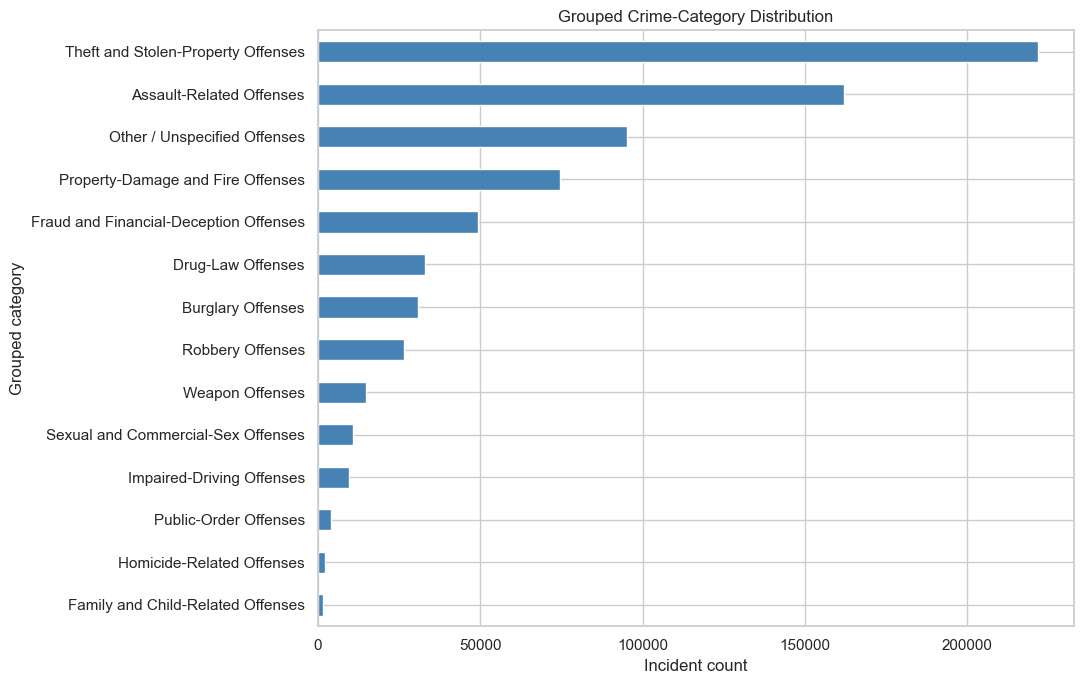

In [3]:
target = "crime_group"
if df[target].isna().any():
    raise ValueError(f"Target contains {int(df[target].isna().sum())} missing labels.")
if df["text_general_code"].isna().any():
    raise ValueError("Original text_general_code contains missing labels; inspect grouped data provenance.")
y_labels = df[target].astype(str)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_labels)
class_names = label_encoder.classes_.tolist()
class_counts = y_labels.value_counts().rename_axis("Grouped crime category").rename("Count").to_frame()
class_counts["Percentage (%)"] = (class_counts["Count"] / len(y_labels) * 100).round(3)
display(class_counts)
print(f"Number of classes: {len(class_names)}")
print("Class names:", class_names)
if len(class_names) != 14:
    raise ValueError(f"Expected 14 grouped classes, found {len(class_names)}.")
assert len(class_counts) == 14
ax = class_counts["Count"].sort_values().plot(kind="barh", figsize=(11, 7), color="steelblue")
ax.set(title="Grouped Crime-Category Distribution", xlabel="Incident count", ylabel="Grouped category")
plt.tight_layout(); plt.show()


## 6. Leakage Exclusions

`ucr_general` is explicitly excluded because it is strongly associated with the original crime label, from which `crime_group` is derived. It must not enter `X`. `text_general_code` is retained only for audit/traceability and is not the target or an input feature. `crime_group` is the sole target. Identifier fields `objectid` and `dc_key`, and administrative/source fields are also excluded.

In [4]:
excluded_predictors = ["ucr_general", "text_general_code", "crime_group", "objectid", "dc_key", "source_year"]
print("Explicitly excluded from X:", excluded_predictors)
assert target == TARGET_GROUPED == "crime_group"
assert "text_general_code" in df.columns  # retained for source-label traceability only


Explicitly excluded from X: ['ucr_general', 'text_general_code', 'crime_group', 'objectid', 'dc_key', 'source_year']


The feature list below is explicit and excludes `ucr_general`, both crime-label columns, and identifier fields. Only event time, district/PSA, and coordinate attributes are considered predictors. Preprocessing receives features only; target data are never passed to imputers, encoders, or scalers.

## 7. Selected-Feature Data Quality Checks

Selected raw fields are checked before the split. Non-finite numeric values are counted and represented as missing in the in-memory feature copy so training-fitted imputers can handle them. No rows are silently removed.

In [5]:
selected_raw = [c for c in ["dispatch_date", "dispatch_date_time", "dispatch_time", "hour", "dc_dist", "psa", "lat", "lng", "point_x", "point_y"] if c in df.columns]
raw_quality = pd.DataFrame({
    "Column": selected_raw,
    "Missing Count": [int(df[c].isna().sum()) for c in selected_raw],
    "Missing Percentage": [(df[c].isna().mean() * 100).round(3) for c in selected_raw],
})
display(raw_quality)


,Column,Missing Count,Missing Percentage
0,dispatch_date,0,0.000
1,dispatch_date_time,0,0.000
2,dispatch_time,0,0.000
3,hour,1603,0.218
4,dc_dist,0,0.000
5,psa,370,0.050
6,lat,2974,0.404
7,lng,2974,0.404
8,point_x,2974,0.404
9,point_y,2974,0.404


## 8. Temporal Feature Preparation

Create calendar and time fields from the incident’s recorded dispatch date/time. `dispatch_date` is preferred for calendar components; `hour` and `dispatch_time` are used when present. Only event-time fields are used, so no future outcome information is introduced. The source CSV remains unchanged.

In [6]:
model_data = create_temporal_features(df)
nonfinite_counts = {}
feature_sources = {}
date_source = "dispatch_date" if "dispatch_date" in df.columns else ("dispatch_date_time" if "dispatch_date_time" in df.columns else None)
if date_source:
    feature_sources["calendar fields"] = date_source
if "hour" in df.columns: feature_sources["hour"] = "hour"
elif "dispatch_time" in df.columns: feature_sources["hour"] = "dispatch_time"
elif "dispatch_date_time" in df.columns: feature_sources["hour"] = "dispatch_date_time"
if "dispatch_time" in df.columns: feature_sources["minute"] = "dispatch_time"
elif "dispatch_date_time" in df.columns: feature_sources["minute"] = "dispatch_date_time"

numeric_candidates = ["lat", "lng", "point_x", "point_y"]
for col in numeric_candidates:
    if col in model_data.columns:
        numeric_values = pd.to_numeric(model_data[col], errors="coerce")
        nonfinite_counts[col] = int((~np.isfinite(numeric_values.dropna())).sum())
        model_data[col] = numeric_values.replace([np.inf, -np.inf], np.nan)
        feature_sources[col] = col
categorical_features = [col for col in ["dc_dist", "psa"] if col in model_data.columns]
for col in categorical_features:
    model_data[col] = model_data[col].astype(object).where(model_data[col].notna(), np.nan)
    feature_sources[col] = col
numeric_features, categorical_features = identify_feature_types(
    model_data, NUMERICAL_FEATURES, CATEGORICAL_FEATURES
)
numeric_features = [c for c in numeric_features if c in model_data.columns]
for col in numeric_features:
    numeric_values = pd.to_numeric(model_data[col], errors="coerce")
    nonfinite_counts[col] = int((~np.isfinite(numeric_values.dropna())).sum())
    model_data[col] = numeric_values.replace([np.inf, -np.inf], np.nan)
feature_names = numeric_features + categorical_features
check_target_leakage(feature_names, target, forbidden_columns=[*LEAKAGE_COLUMNS, *IDENTIFIER_COLUMNS, "source_year"])
X = model_data[feature_names].copy()
print("Feature sources:", feature_sources)
print("Selected input columns:", feature_names)
print("Categorical features:", categorical_features)
print("Numerical features:", numeric_features)
print("Non-finite numeric values by field:", nonfinite_counts)
feature_quality = pd.DataFrame([{
    "Feature": col, "Missing values": int(X[col].isna().sum()),
    "Missing (%)": round(float(X[col].isna().mean() * 100), 4),
    "Non-finite numeric values": nonfinite_counts.get(col, 0),
} for col in feature_names])
display(feature_quality)
print("Rows excluded during feature preparation:", len(df) - len(X))
assert target not in X.columns
assert len(X) == len(df), "Feature preparation changed the row count."
print("Leakage check passed; all records remain in X.")

assert len(feature_names) == 14
assert feature_names == [
    "year", "month", "day_of_week", "day_of_month", "day_of_year", "week_of_year",
    "hour", "minute", "lat", "lng", "point_x", "point_y", "dc_dist", "psa",
]
assert not set(["ucr_general", "text_general_code", "crime_group", "objectid", "dc_key", "source_year"]).intersection(X.columns)

assert not set(["ucr_general", "text_general_code", "crime_group", "objectid", "dc_key", "source_year"]).intersection(X.columns)
assert "crime_group" not in X.columns


Feature sources: {'calendar fields': 'dispatch_date', 'hour': 'hour', 'minute': 'dispatch_time', 'lat': 'lat', 'lng': 'lng', 'point_x': 'point_x', 'point_y': 'point_y', 'dc_dist': 'dc_dist', 'psa': 'psa'}
Selected input columns: ['year', 'month', 'day_of_week', 'day_of_month', 'day_of_year', 'week_of_year', 'hour', 'minute', 'lat', 'lng', 'point_x', 'point_y', 'dc_dist', 'psa']
Categorical features: ['dc_dist', 'psa']
Numerical features: ['year', 'month', 'day_of_week', 'day_of_month', 'day_of_year', 'week_of_year', 'hour', 'minute', 'lat', 'lng', 'point_x', 'point_y']
Non-finite numeric values by field: {'lat': 0, 'lng': 0, 'point_x': 0, 'point_y': 0, 'year': 0, 'month': 0, 'day_of_week': 0, 'day_of_month': 0, 'day_of_year': 0, 'week_of_year': 0, 'hour': 0, 'minute': 0}


,Feature,Missing values,Missing (%),Non-finite numeric values
0,year,0,0.0000,0
1,month,0,0.0000,0
2,day_of_week,0,0.0000,0
3,day_of_month,0,0.0000,0
4,day_of_year,0,0.0000,0
5,week_of_year,0,0.0000,0
6,hour,1603,0.2178,0
7,minute,0,0.0000,0
8,lat,2974,0.4041,0
9,lng,2974,0.4041,0


Rows excluded during feature preparation: 0
Leakage check passed; all records remain in X.


## 9. Stratified Train/Test Split

Split all records into 70% training and 30% testing partitions using `random_state=42` and stratification on `crime_group`. Rare classes are retained. Overall, training, and test class distributions are displayed and compared.

In [7]:
X_train, X_test, y_train, y_test = create_train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=True
)
split_feasible = True
print(f"Training rows: {len(X_train):,}")
print(f"Testing rows: {len(X_test):,}")
assert len(X_train) + len(X_test) == len(df)

overall_dist = pd.Series(y).value_counts().reindex(range(len(class_names)), fill_value=0)
train_dist = pd.Series(y_train).value_counts().reindex(range(len(class_names)), fill_value=0)
test_dist = pd.Series(y_test).value_counts().reindex(range(len(class_names)), fill_value=0)
split_distribution = pd.DataFrame({
    "Grouped Crime Category": class_names,
    "Overall Count": overall_dist.to_numpy(),
    "Overall (%)": (overall_dist.to_numpy() / len(y) * 100).round(3),
    "Train Count": train_dist.to_numpy(),
    "Train (%)": (train_dist.to_numpy() / len(y_train) * 100).round(3),
    "Test Count": test_dist.to_numpy(),
    "Test (%)": (test_dist.to_numpy() / len(y_test) * 100).round(3),
})
display(split_distribution)
print("Stratification succeeded:", split_feasible)

assert len(X_train) == 515223 and len(X_test) == 220810
assert TEST_SIZE == 0.30 and RANDOM_STATE == 42


Training rows: 515,223
Testing rows: 220,810


,Grouped Crime Category,Overall Count,Overall (%),Train Count,Train (%),Test Count,Test (%)
0,Assault-Related Offenses,162012,22.012,113408,22.011,48604,22.012
1,Burglary Offenses,30742,4.177,21519,4.177,9223,4.177
2,Drug-Law Offenses,33032,4.488,23122,4.488,9910,4.488
3,Family and Child-Related Offenses,1486,0.202,1040,0.202,446,0.202
4,Fraud and Financial-Deception Offenses,49240,6.690,34468,6.690,14772,6.690
5,Homicide-Related Offenses,2287,0.311,1601,0.311,686,0.311
6,Impaired-Driving Offenses,9470,1.287,6629,1.287,2841,1.287
7,Other / Unspecified Offenses,95265,12.943,66686,12.943,28579,12.943
8,Property-Damage and Fire Offenses,74555,10.129,52189,10.129,22366,10.129
9,Public-Order Offenses,4042,0.549,2830,0.549,1212,0.549


Stratification succeeded: True


## 10. Train-Fitted Preprocessing

Nominal `dc_dist` and `psa` values are imputed with training-set modes and one-hot encoded. Numerical values use training-set median imputation; MLP and KNN additionally receive standardized numeric variables. Trees use unscaled numeric fields. Each model uses a scikit-learn pipeline that fits its preprocessing only on `X_train` and applies the learned transformations to `X_test`.

In [8]:
dimension_probe = build_preprocessor(numeric_features, categorical_features, scale_numeric=False)
dimension_probe.fit(X_train)
feature_count = dimension_probe.transform(X_train.iloc[:min(1000, len(X_train))]).shape[1]
print(f"Feature matrix dimensions: train {len(X_train):,} × {feature_count}; test {len(X_test):,} × {feature_count}")
display(pd.DataFrame({"Transformed Feature": dimension_probe.get_feature_names_out()}))

assert feature_count == 39


Feature matrix dimensions: train 515,223 × 39; test 220,810 × 39


,Transformed Feature
0,numeric__year
1,numeric__month
2,numeric__day_of_week
3,numeric__day_of_month
4,numeric__day_of_year
5,numeric__week_of_year
6,numeric__hour
7,numeric__minute
8,numeric__lat
9,numeric__lng


## 11. Model Initialization

The notebook imports the six existing model factories. Baseline parameters are defined in their respective `models/*.py` files; there is no tuning. MLP and KNN pipelines use scaled numerical inputs, while tree-based estimators use unscaled numeric features.

In [9]:
model_specs = {
    "XGBoost": (create_xgboost_model(num_classes=len(class_names), random_state=RANDOM_STATE), False),
    "CatBoost": (create_catboost_model(random_state=RANDOM_STATE), False),
    "Random Forest": (create_random_forest_model(random_state=RANDOM_STATE), False),
    "Decision Tree": (create_decision_tree_model(random_state=RANDOM_STATE), False),
    "MLP": (create_mlp_model(random_state=RANDOM_STATE), True),
    "KNN": (create_knn_model(), True),
}
models = {
    name: build_model_pipeline(estimator, numeric_features, categorical_features, scale_numeric=scale)
    for name, (estimator, scale) in model_specs.items()
}
print("Initialized models:", list(models))


Initialized models: ['XGBoost', 'CatBoost', 'Random Forest', 'Decision Tree', 'MLP', 'KNN']


## 12. Model Training and Prediction

Each model receives the same train/test records and selected predictors. Per-model training, prediction, and total elapsed times are recorded.

In [10]:
fitted_models = {}
predictions = {}
timings = {}
for name, pipeline in models.items():
    print(f"Training {name} ...", flush=True)
    total_start = time.perf_counter()
    train_start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    train_seconds = time.perf_counter() - train_start
    predict_start = time.perf_counter()
    pred = np.asarray(pipeline.predict(X_test), dtype=int)
    predict_seconds = time.perf_counter() - predict_start
    fitted_models[name] = pipeline
    predictions[name] = pred
    timings[name] = {
        "Training Time (s)": train_seconds,
        "Prediction Time (s)": predict_seconds,
        "Total Execution Time (s)": time.perf_counter() - total_start,
    }
    print(f"{name}: train={train_seconds:.1f}s, predict={predict_seconds:.1f}s", flush=True)
assert len(fitted_models) == 6 and len(predictions) == 6
assert all(len(pred) == len(y_test) for pred in predictions.values())

Training XGBoost ...


XGBoost: train=36.9s, predict=1.1s


Training CatBoost ...


CatBoost: train=38.6s, predict=0.2s


Training Random Forest ...


...

Training MLP ...


MLP: train=56.8s, predict=0.2s


Training KNN ...


C:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 

KNN: train=0.7s, predict=94.2s


## 13. Evaluation Metrics and Classification Reports

For each model, calculate accuracy, weighted precision/recall/F1, and macro precision/recall/F1 with zero-division handling. A full class-wise classification report is also generated for every classifier.

In [11]:
metric_rows = []
classification_reports = {}
if split_feasible:
    for name, pred in predictions.items():
        metrics = evaluate_multiclass_model(y_test, pred)
        metric_rows.append(add_model_result(name, metrics, timings[name]))
        classification_reports[name] = generate_classification_report(
            y_test, pred, labels=np.arange(len(class_names)), target_names=class_names
        )
        print(f"{name} classification report:")
        display(classification_reports[name])
    results = pd.DataFrame(metric_rows).sort_values("Model").reset_index(drop=True)
    format_map = {c: "{:.4f}" for c in results.select_dtypes(include="number").columns if "Time" not in c}
    display(results.style.format(format_map))
else:
    results = pd.DataFrame(columns=["Model", "Accuracy", "Weighted Precision", "Weighted Recall", "Weighted F1", "Macro Precision", "Macro Recall", "Macro F1", "Training Time (s)", "Prediction Time (s)"])
    print("Evaluation metrics and classification reports are unavailable because no models were trained.")


XGBoost classification report:


,precision,recall,f1-score,support
Assault-Related Offenses,0.301664,0.421550,0.351670,48604.000000
Burglary Offenses,0.509499,0.031985,0.060192,9223.000000
Drug-Law Offenses,0.449945,0.248537,0.320203,9910.000000
Family and Child-Related Offenses,0.539924,0.318386,0.400564,446.000000
Fraud and Financial-Deception Offenses,0.651852,0.011914,0.023401,14772.000000
Homicide-Related Offenses,0.326905,0.518950,0.401127,686.000000
Impaired-Driving Offenses,0.653409,0.080957,0.144065,2841.000000
Other / Unspecified Offenses,0.428435,0.297246,0.350982,28579.000000
Property-Damage and Fire Offenses,0.298246,0.000760,0.001516,22366.000000
Public-Order Offenses,0.620690,0.074257,0.132646,1212.000000


CatBoost classification report:


,precision,recall,f1-score,support
Assault-Related Offenses,0.292067,0.392396,0.334878,48604.000000
Burglary Offenses,0.545455,0.001952,0.003889,9223.000000
Drug-Law Offenses,0.389657,0.218971,0.280380,9910.000000
Family and Child-Related Offenses,0.000000,0.000000,0.000000,446.000000
Fraud and Financial-Deception Offenses,0.928571,0.001760,0.003514,14772.000000
Homicide-Related Offenses,0.385455,0.309038,0.343042,686.000000
Impaired-Driving Offenses,0.000000,0.000000,0.000000,2841.000000
Other / Unspecified Offenses,0.385932,0.253228,0.305804,28579.000000
Property-Damage and Fire Offenses,0.000000,0.000000,0.000000,22366.000000
Public-Order Offenses,0.000000,0.000000,0.000000,1212.000000


Random Forest classification report:


...

MLP classification report:


,precision,recall,f1-score,support
Assault-Related Offenses,0.288073,0.440046,0.348200,48604.000000
Burglary Offenses,0.000000,0.000000,0.000000,9223.000000
Drug-Law Offenses,0.377525,0.207467,0.267778,9910.000000
Family and Child-Related Offenses,0.000000,0.000000,0.000000,446.000000
Fraud and Financial-Deception Offenses,0.484848,0.002166,0.004313,14772.000000
Homicide-Related Offenses,0.363881,0.196793,0.255440,686.000000
Impaired-Driving Offenses,0.476190,0.003520,0.006988,2841.000000
Other / Unspecified Offenses,0.380127,0.293817,0.331445,28579.000000
Property-Damage and Fire Offenses,0.000000,0.000000,0.000000,22366.000000
Public-Order Offenses,0.866667,0.010726,0.021190,1212.000000


KNN classification report:


,precision,recall,f1-score,support
Assault-Related Offenses,0.264462,0.423936,0.325727,48604.000000
Burglary Offenses,0.108355,0.064404,0.080789,9223.000000
Drug-Law Offenses,0.243343,0.233300,0.238215,9910.000000
Family and Child-Related Offenses,0.194656,0.114350,0.144068,446.000000
Fraud and Financial-Deception Offenses,0.141850,0.096737,0.115029,14772.000000
Homicide-Related Offenses,0.098039,0.021866,0.035757,686.000000
Impaired-Driving Offenses,0.265675,0.087997,0.132205,2841.000000
Other / Unspecified Offenses,0.322498,0.308618,0.315406,28579.000000
Property-Damage and Fire Offenses,0.137700,0.082715,0.103349,22366.000000
Public-Order Offenses,0.257384,0.100660,0.144721,1212.000000


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro Precision,Macro Recall,Macro F1,Training Time (s),Prediction Time (s),Total Execution Time (s)
0,CatBoost,0.3662,0.3561,0.3662,0.2867,0.2733,0.1401,0.1286,38.616112,0.225365,38.841484
1,Decision Tree,0.2926,0.2961,0.2926,0.2942,0.2035,0.2062,0.2047,8.476239,0.216710,8.692955
2,KNN,0.2990,0.2759,0.2990,0.2795,0.2004,0.1476,0.1573,0.708470,94.195503,94.903983
3,MLP,0.3661,0.3063,0.3661,0.2919,0.2770,0.1349,0.1261,56.839314,0.248940,57.088261
4,Random Forest,0.4216,0.4216,0.4216,0.3691,0.5038,0.2241,0.2568,14.769602,1.726744,16.496352
5,XGBoost,0.3828,0.4002,0.3828,0.3111,0.4582,0.2054,0.2070,36.917559,1.052467,37.970034


## 14. Confusion Matrices

Generate one readable full-size confusion matrix per model using the same fixed ordering of the 14 grouped labels. No classes are collapsed in the plots.

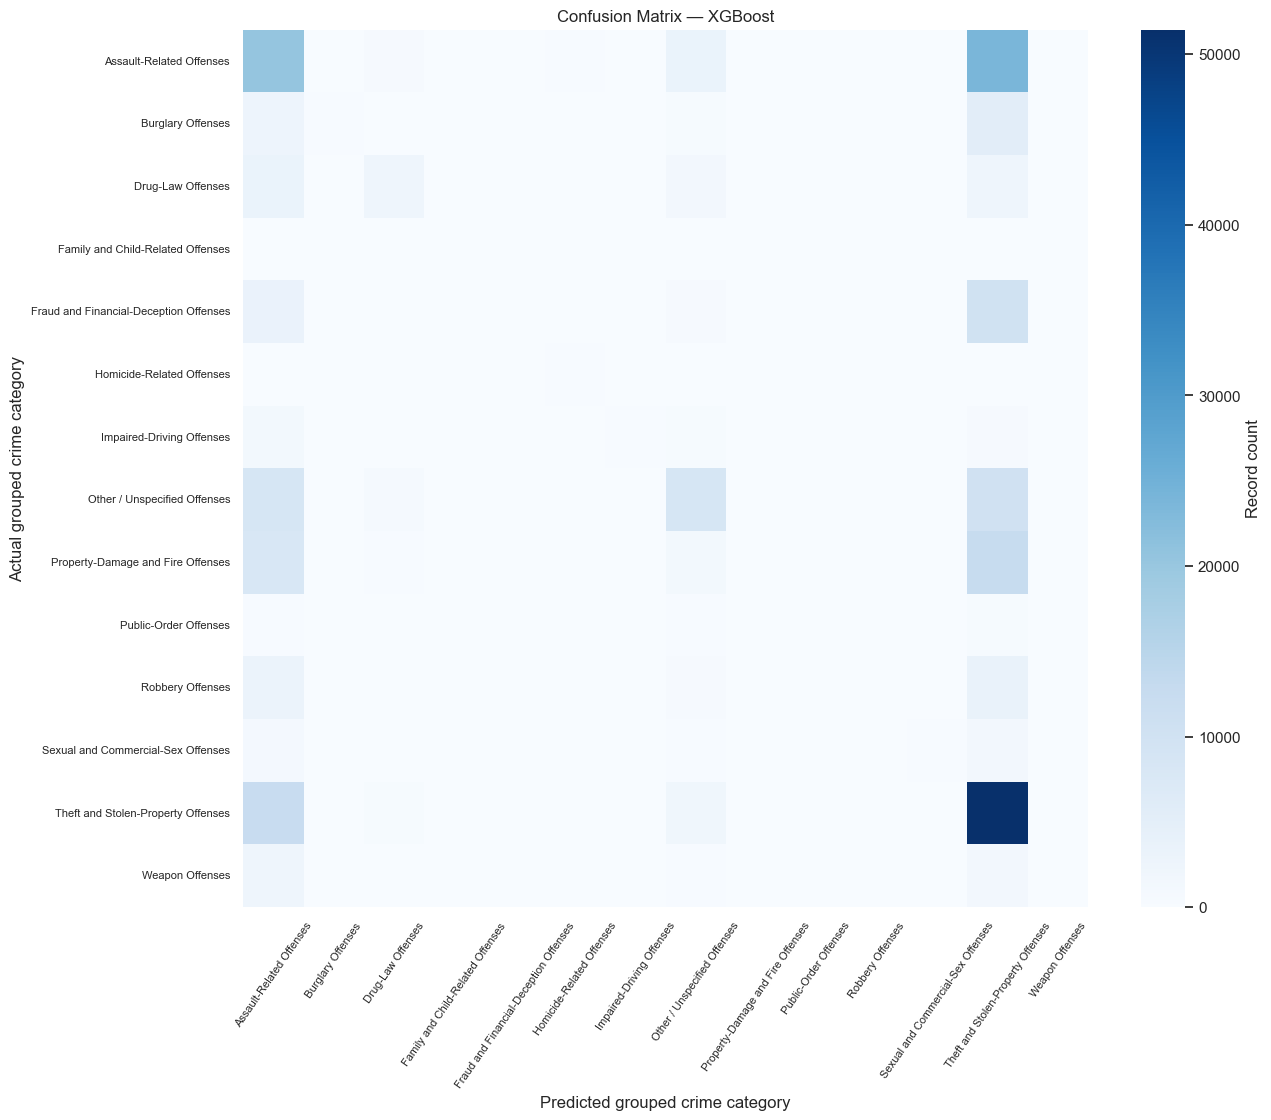

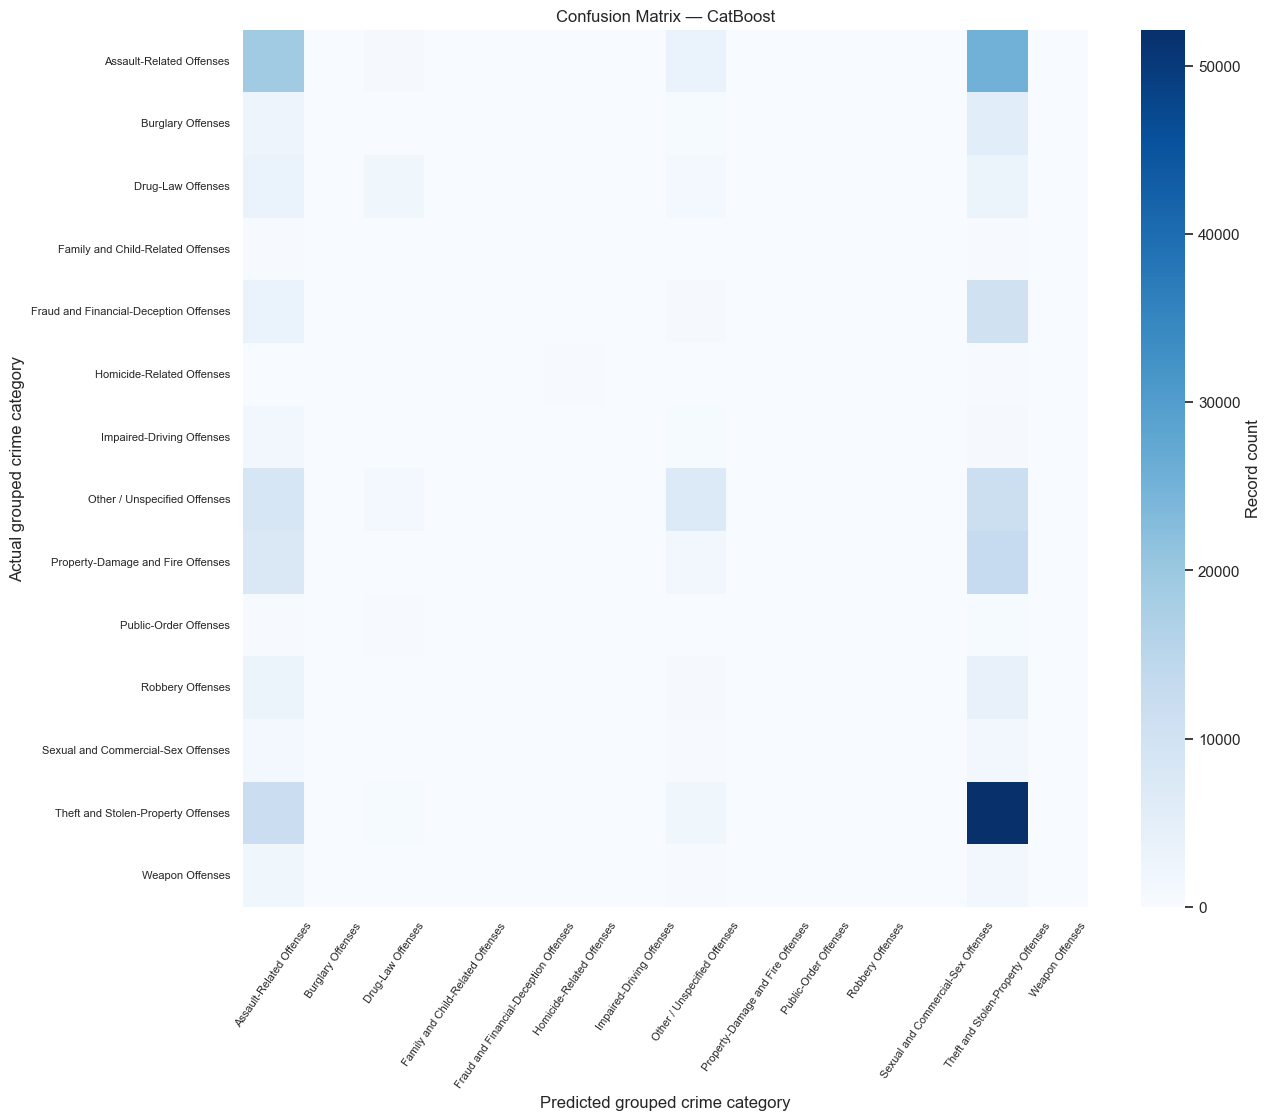

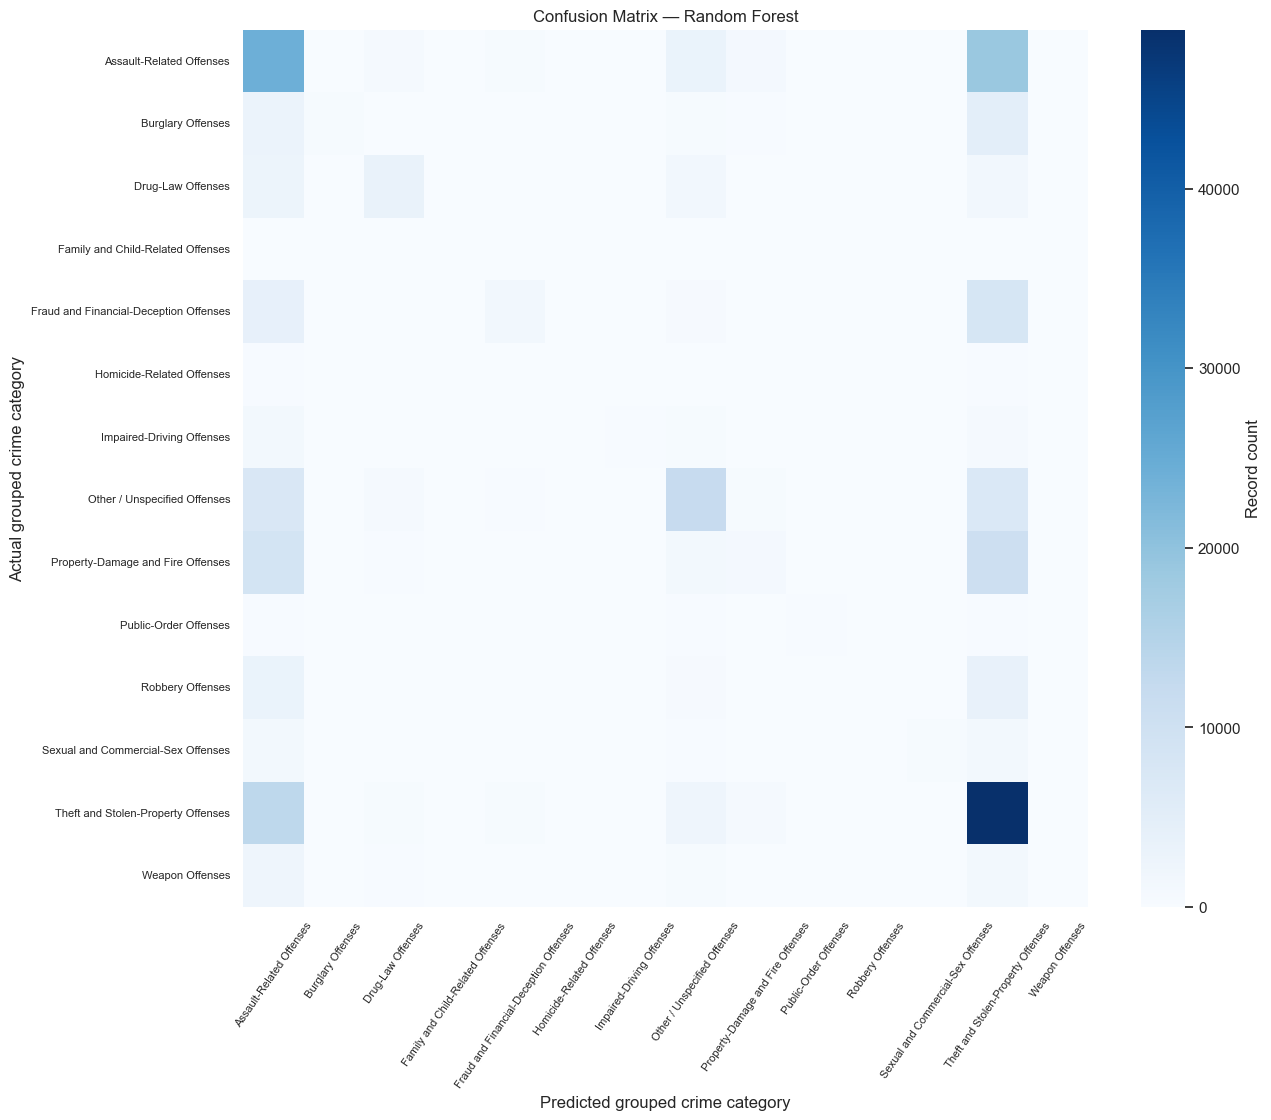

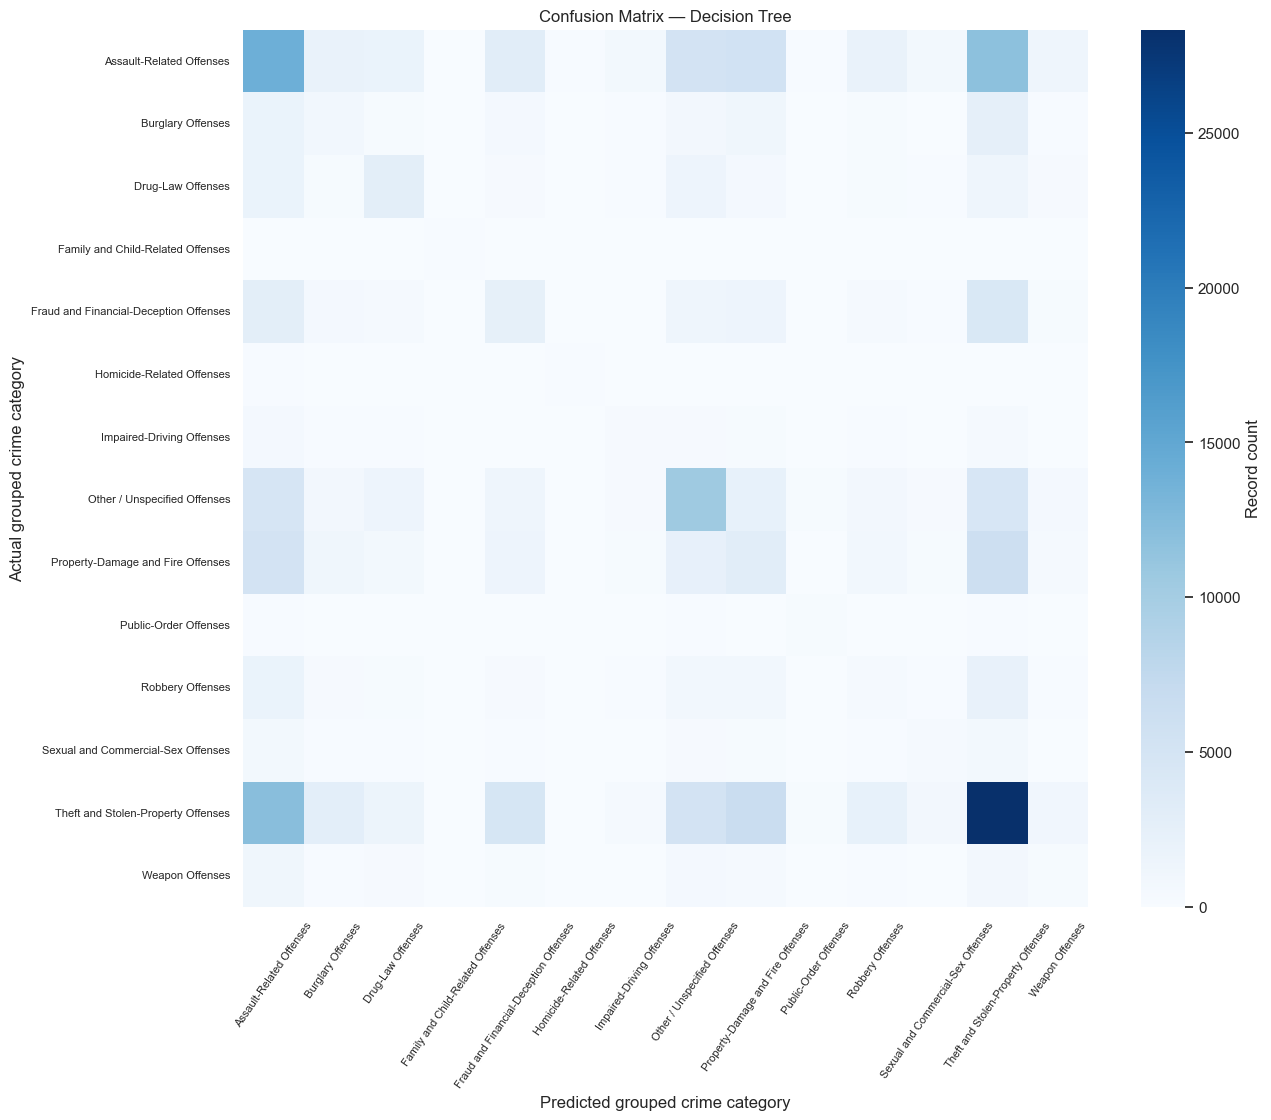

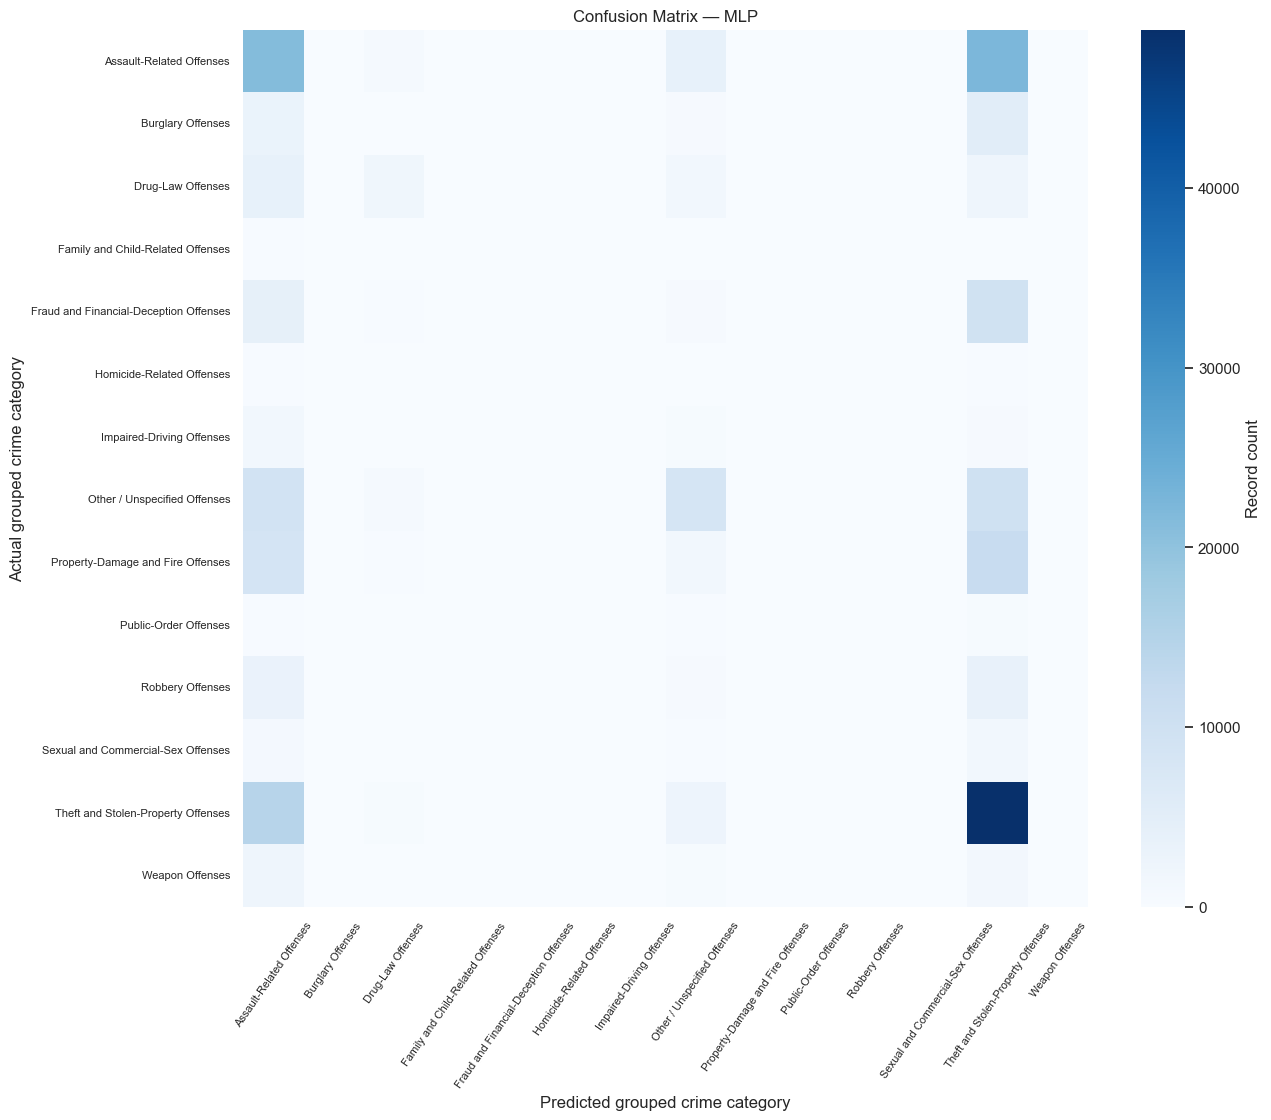

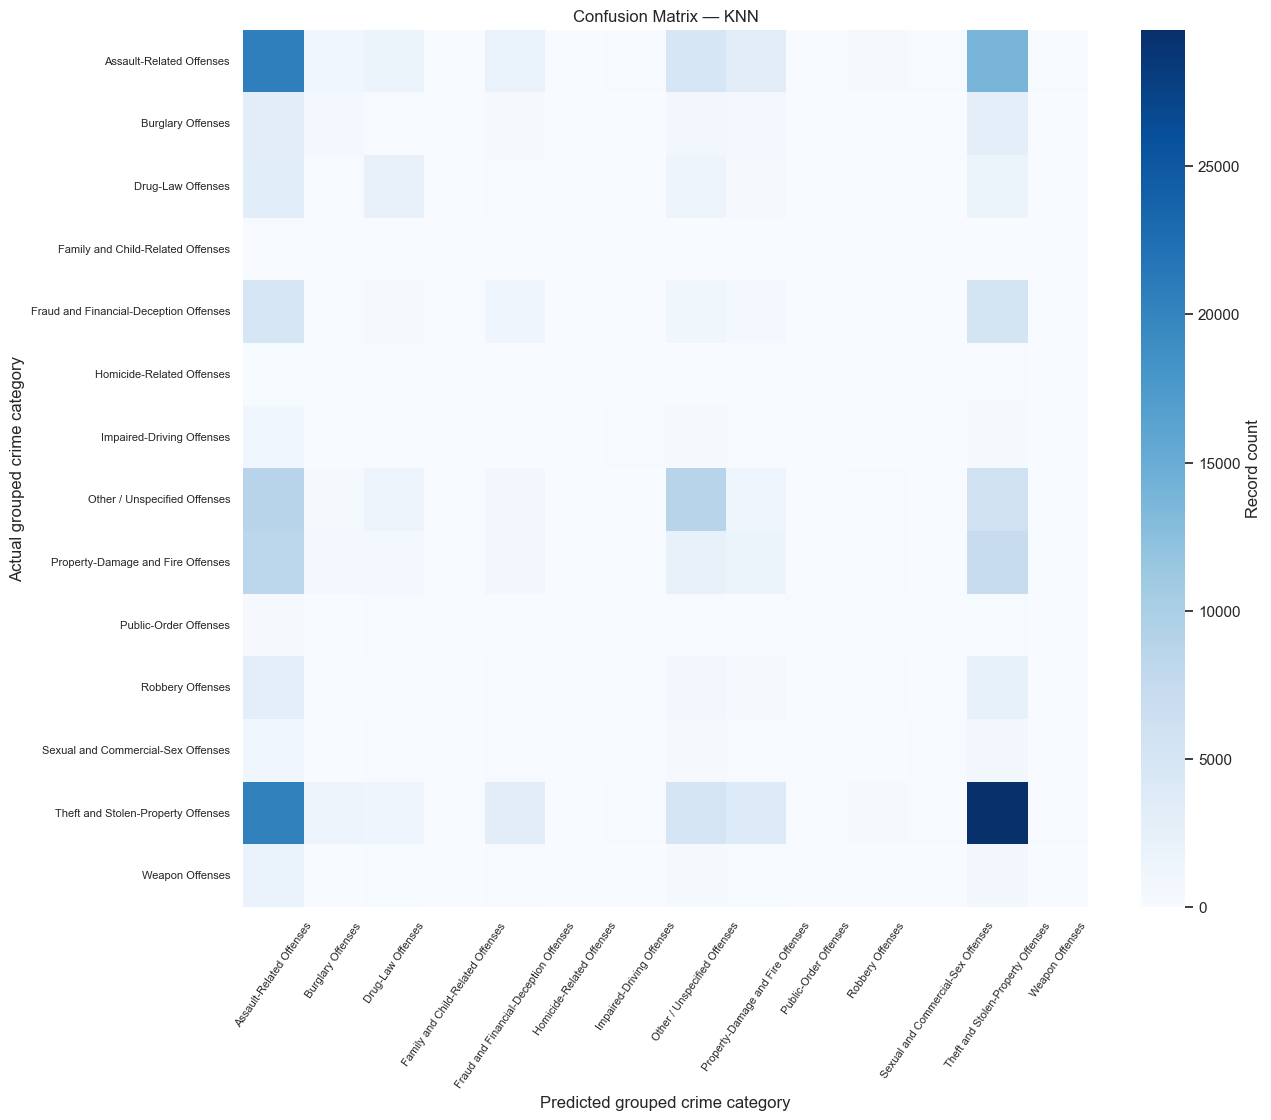

In [12]:
for name, pred in predictions.items():
    cm_data = create_confusion_matrix_data(y_test, pred, labels=np.arange(len(class_names)), display_labels=class_names)
    fig, ax = plot_confusion_matrix(cm_data, title=f"Confusion Matrix — {name}", figsize=(14, 12))
    ax.set(xlabel="Predicted grouped crime category", ylabel="Actual grouped crime category")
    ax.tick_params(axis="x", labelrotation=55, labelsize=8)
    ax.tick_params(axis="y", labelrotation=0, labelsize=8)
    plt.show()


## 15. Model Comparison

Sort models by weighted F1 for readability. This is a comparison on this one split, not a claim of a universally best model. Accuracy, weighted F1, and macro F1 are plotted on the same 0–1 scale.

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro Precision,Macro Recall,Macro F1,Training Time (s),Prediction Time (s),Total Execution Time (s)
0,Random Forest,0.4216,0.4216,0.4216,0.3691,0.5038,0.2241,0.2568,14.769602,1.726744,16.496352
1,XGBoost,0.3828,0.4002,0.3828,0.3111,0.4582,0.2054,0.2070,36.917559,1.052467,37.970034
2,Decision Tree,0.2926,0.2961,0.2926,0.2942,0.2035,0.2062,0.2047,8.476239,0.216710,8.692955
3,MLP,0.3661,0.3063,0.3661,0.2919,0.2770,0.1349,0.1261,56.839314,0.248940,57.088261
4,CatBoost,0.3662,0.3561,0.3662,0.2867,0.2733,0.1401,0.1286,38.616112,0.225365,38.841484
5,KNN,0.2990,0.2759,0.2990,0.2795,0.2004,0.1476,0.1573,0.708470,94.195503,94.903983


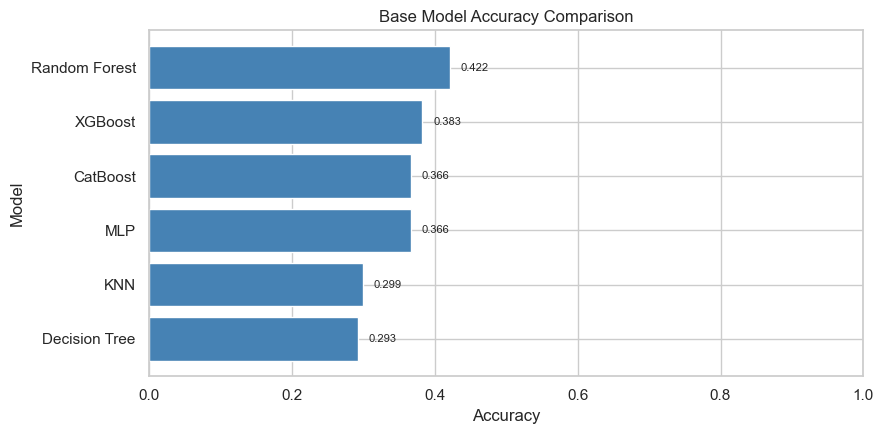

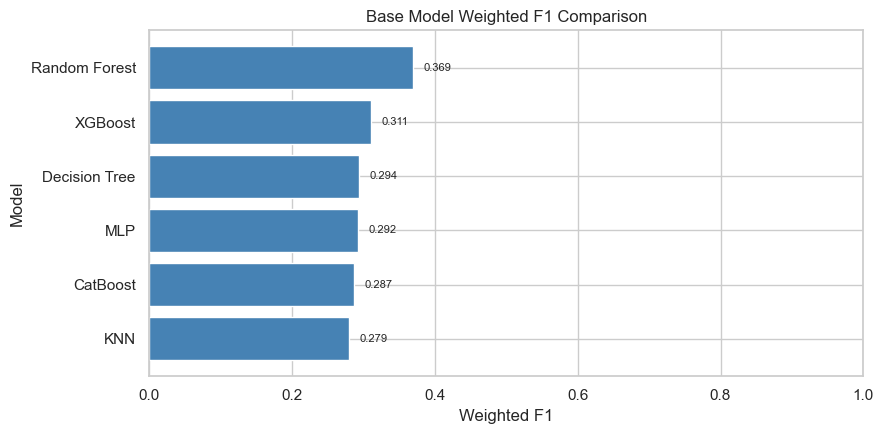

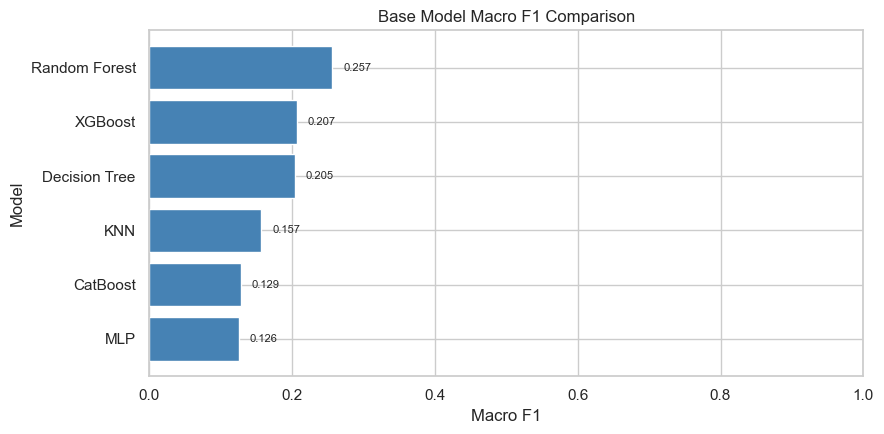

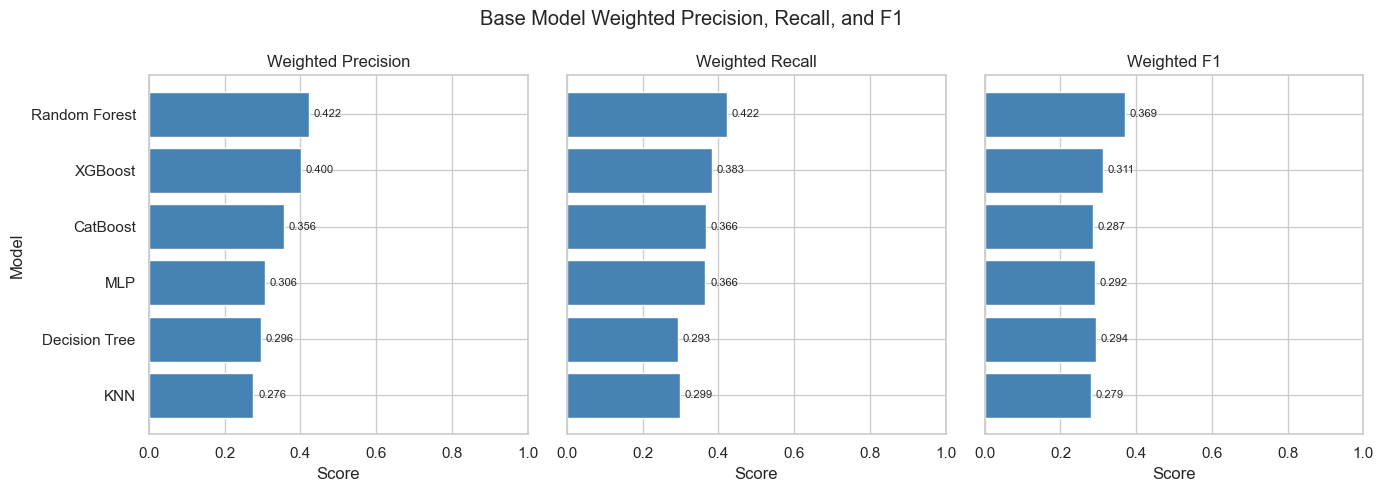

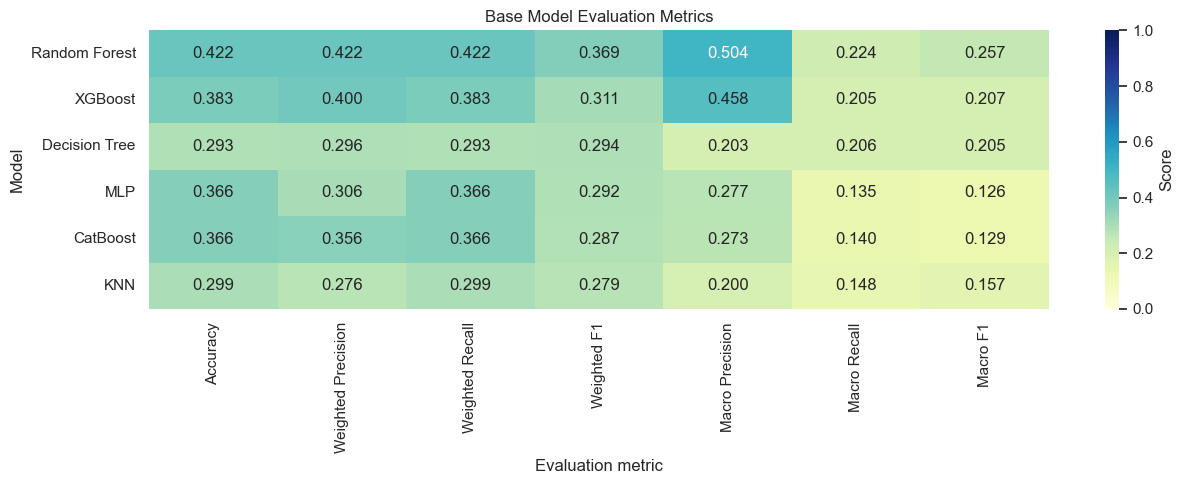

Rows in model comparison: 6


In [13]:
results = create_model_comparison_table(results, sort_by="Weighted F1", ascending=False)
display(results.style.format({c: "{:.4f}" for c in results.select_dtypes(include="number").columns if "Time" not in c}))
for metric, title in [("Accuracy", "Base Model Accuracy Comparison"), ("Weighted F1", "Base Model Weighted F1 Comparison"), ("Macro F1", "Base Model Macro F1 Comparison")]:
    fig, ax = plot_model_comparison(results, metric, figsize=(9, 4.5), xlim=(0, 1))
    ax.set_title(title)
    plt.show()

fig, axes = plot_weighted_metrics(results, figsize=(14, 5))
plt.show()
fig, ax = plot_model_metric_summary(results, figsize=(13, 5))
plt.show()
print("Rows in model comparison:", len(results))


### Metric-Specific Highest Observations

The next cell reports the highest value observed for each evaluation metric. This is a descriptive comparison of this experiment, not a claim that one model is universally best.

In [14]:
for metric in ["Accuracy", "Weighted Precision", "Weighted Recall", "Weighted F1", "Macro Precision", "Macro Recall", "Macro F1"]:
    row = results.loc[results[metric].idxmax()]
    print(f"Highest observed {metric}: {row['Model']} = {row[metric]:.4f}")

Highest observed Accuracy: Random Forest = 0.4216
Highest observed Weighted Precision: Random Forest = 0.4216
Highest observed Weighted Recall: Random Forest = 0.4216
Highest observed Weighted F1: Random Forest = 0.3691
Highest observed Macro Precision: Random Forest = 0.5038
Highest observed Macro Recall: Random Forest = 0.2241
Highest observed Macro F1: Random Forest = 0.2568


## 17. Class Imbalance

The semantically grouped dataset remains naturally imbalanced. No oversampling or undersampling is applied. Accuracy and weighted metrics reflect the frequency distribution, while macro F1 gives equal weight to each grouped category and helps show performance on smaller groups.

In [15]:
imbalance_summary = pd.DataFrame({
    "Class count": y_labels.value_counts(),
    "Share (%)": (y_labels.value_counts(normalize=True) * 100).round(3),
})
print(f"Largest class share: {imbalance_summary['Share (%)'].max():.2f}%")
print(f"Smallest class count: {int(imbalance_summary['Class count'].min()):,}")
display(imbalance_summary.sort_values("Class count"))


Largest class share: 30.14%
Smallest class count: 1,486


,Class count,Share (%)
crime_group,,
Family and Child-Related Offenses,1486,0.202
Homicide-Related Offenses,2287,0.311
Public-Order Offenses,4042,0.549
Impaired-Driving Offenses,9470,1.287
Sexual and Commercial-Sex Offenses,10752,1.461
Weapon Offenses,14952,2.031
Robbery Offenses,26385,3.585
Burglary Offenses,30742,4.177
Drug-Law Offenses,33032,4.488


## 18. Comparison With Base Paper

The source paper’s Philadelphia results reflect its own data scope, labels, features, and experimental setup. This experiment uses the Philadelphia 2018–2022 grouped dataset and a teacher-requested 14-class semantic mapping documented in `02_Crime_Class_Grouping.ipynb`. The mapping is project-specific; the exact 14 categories are not attributed to the paper, and its reported XGBoost accuracy is only a reference point, not a target.

## 19. Limitations

- The grouped categories combine several distinct original labels; the mapping is fully documented for traceability.
- `ucr_general`, `text_general_code`, `crime_group`, identifiers, and `source_year` are excluded from predictors to reduce leakage.
- The random stratified split assesses records from the same overall period and does not measure future-year generalization.
- Baseline settings are not tuned; MLP convergence and runtime should be considered when interpreting results.
- Recorded incidents and these fields do not establish causes or population-level crime risk.

## 20. Observations and Conclusion

The following observations are generated from the measured results, followed by a concise conclusion about this baseline experiment.

## 16. Verify Saved Results (Read-Only)

Compare this verification run against the already saved result table. This presentation pass does not rewrite the verified result or classification-report CSV files.


In [16]:
comparison_path = RESULTS_DIR / "base_model_comparison_grouped.csv"
reference_metrics = pd.read_csv(comparison_path).sort_values("Model").reset_index(drop=True)
new_metrics = results.sort_values("Model").reset_index(drop=True)
metric_columns = ["Accuracy", "Weighted Precision", "Weighted Recall", "Weighted F1", "Macro Precision", "Macro Recall", "Macro F1"]
assert new_metrics["Model"].tolist() == reference_metrics["Model"].tolist()
comparison = pd.DataFrame({"Model": new_metrics["Model"]})
for metric in metric_columns:
    comparison[f"{metric} difference"] = new_metrics[metric] - reference_metrics[metric]
display(comparison)
max_metric_difference = float(np.abs(comparison[[f"{m} difference" for m in metric_columns]].to_numpy()).max())
print("Maximum absolute metric difference:", max_metric_difference)
print("Result CSV and six classification-report CSVs were read only.")
assert max_metric_difference <= 1e-12
assert len(results) == 6 and len(classification_reports) == 6


,Model,Accuracy difference,Weighted Precision difference,Weighted Recall difference,Weighted F1 difference,Macro Precision difference,Macro Recall difference,Macro F1 difference
0,CatBoost,5.551115e-17,5.551115e-17,5.551115e-17,5.551115e-17,0.000000e+00,5.551115e-17,0.000000e+00
1,Decision Tree,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.775558e-17,2.775558e-17
2,KNN,5.551115e-17,0.000000e+00,5.551115e-17,0.000000e+00,2.775558e-17,2.775558e-17,5.551115e-17
3,MLP,5.551115e-17,0.000000e+00,5.551115e-17,0.000000e+00,5.551115e-17,0.000000e+00,0.000000e+00
4,Random Forest,5.551115e-17,0.000000e+00,5.551115e-17,5.551115e-17,0.000000e+00,5.551115e-17,5.551115e-17
5,XGBoost,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.551115e-17,5.551115e-17


Maximum absolute metric difference: 5.551115123125783e-17
Result CSV and six classification-report CSVs were read only.


In [17]:
for metric in ["Accuracy", "Weighted F1", "Macro F1"]:
    row = results.loc[results[metric].idxmax()]
    print(f"Highest observed {metric}: {row['Model']} ({row[metric]:.4f})")
print("Interpret these as metric-specific outcomes on one holdout split; they do not establish universal superiority.")

Highest observed Accuracy: Random Forest (0.4216)
Highest observed Weighted F1: Random Forest (0.3691)
Highest observed Macro F1: Random Forest (0.2568)
Interpret these as metric-specific outcomes on one holdout split; they do not establish universal superiority.


### Conclusion

Six base-paper-aligned classifiers were evaluated on the teacher-approved 14-class grouped target using a reproducible stratified holdout split. The original crime label remains in the data for audit but is not used as the target or a predictor. Results and per-model reports are saved under `results/`.